# Notebook 3: Appliance-Disaggregation (NILM) Model & Evaluation

## Objective
This notebook fulfills **Section 3** of the Flock Energy take-home assignment. It builds, trains, and evaluates a Non-Intrusive Load Monitoring (NILM) machine learning model to disaggregate washing-machine power from whole-home aggregate load profiles at a **1-minute resolution** using the official cleaned REFIT dataset.

## Structure & Workflow
- **Cell 2:** Environment setup, mounting Google Drive, and loading cleaned household data (Houses 1, 2, 3, and 5).
- **Cell 3:** Feature engineering pipeline (extracting rolling statistics, temporal features, and aggregate power lags).
- **Cell 4:** Cross-household train/test split strategy (Training on Houses 1, 2, and 3; Testing unseen generalization on House 5) to eliminate data leakage.
- **Cell 5:** Model training (Random Forest Regressor) alongside a simple baseline ("Always-Off" baseline).
- **Cell 6:** Evaluation metrics (MAE, RMSE, On/Off F1-score) and actual-vs-predicted visualization.
- **Cell 7:** Failure case analysis (identifying situations where the model struggles due to overlapping appliance signatures).

**Drive Mounting & Data Loading**

In [1]:
# 1. Install required library for handling .7z archives
!pip install -q py7zr

# 2. Mount Google Drive and Extract Clean Dataset if missing
from google.colab import drive
drive.mount('/content/drive')

import os
import glob
import py7zr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, f1_score

CLEAN_ARCHIVE = "/content/drive/MyDrive/Flock Energy - Take Home Assignment /CLEAN_REFIT_081116.7z"
CLEAN_DIR = "/content/data/clean"
os.makedirs(CLEAN_DIR, exist_ok=True)

if not glob.glob(f"{CLEAN_DIR}/**/*.csv", recursive=True):
    print("Extracting Clean REFIT Dataset...")
    with py7zr.SevenZipFile(CLEAN_ARCHIVE, mode='r') as z:
        z.extractall(CLEAN_DIR)

# 3. Load Clean REFIT Households with Robust File Matching
target_houses = ["House1", "House2", "House3", "House5"]
house_data = {}
clean_files = glob.glob(f"{CLEAN_DIR}/**/*.csv", recursive=True)

for house in target_houses:
    match = [f for f in clean_files if house.lower() in f.lower() or house.replace("House", "House_") in f]
    if not match:
        print(f"❌ Error: Could not find clean file for {house}")
        continue

    filepath = match[0]
    df = pd.read_csv(filepath)

    # Standardise time column and index
    time_col = [c for c in df.columns if "time" in c.lower() or "date" in c.lower()][0]
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.set_index(time_col).sort_index()

    # Identify washing machine column based on REFIT naming conventions
    wm_mapping = {"House1": "Appliance1", "House2": "Appliance2", "House3": "Appliance6", "House5": "Appliance1"}
    wm_col_name = wm_mapping.get(house)

    if wm_col_name not in df.columns:
        wm_col = [c for c in df.columns if "washing" in c.lower() or "wm" in c.lower()]
        wm_col_name = wm_col[0] if wm_col else df.columns[2]

    house_data[house] = {"df": df, "wm_col": wm_col_name}
    print(f"✅ Successfully Loaded {house} | Rows: {len(df):,} | WM Column: {wm_col_name}")

print(f"\nLoaded households dictionary keys: {list(house_data.keys())}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Successfully Loaded House1 | Rows: 4,431,541 | WM Column: Appliance1
✅ Successfully Loaded House2 | Rows: 5,168,605 | WM Column: Appliance2
✅ Successfully Loaded House3 | Rows: 6,994,594 | WM Column: Appliance6
✅ Successfully Loaded House5 | Rows: 7,430,755 | WM Column: Appliance1

Loaded households dictionary keys: ['House1', 'House2', 'House3', 'House5']


**Feature Engineering Pipeline**

In [2]:
def extract_nilm_features(df, agg_col='Aggregate'):
    """
    Extracts rolling window statistics and temporal features from aggregate power
    to capture transient appliance signatures.
    """
    feats = pd.DataFrame(index=df.index)
    agg = df[agg_col].fillna(0)

    feats['agg_power'] = agg

    # Rolling statistics across multiple time windows (3, 7, 15 minutes)
    for w in [3, 7, 15]:
        feats[f'rolling_mean_{w}'] = agg.rolling(w, center=True).mean()
        feats[f'rolling_std_{w}'] = agg.rolling(w, center=True).std()
        feats[f'rolling_max_{w}'] = agg.rolling(w, center=True).max()

    # Temporal features
    feats['hour'] = df.index.hour
    feats['dayofweek'] = df.index.dayofweek

    return feats.dropna()

print("Feature engineering pipeline ready.")

Feature engineering pipeline ready.


**Train/Test Split & Leakage Prevention Strategy**

In [3]:
"""
Split Strategy: Cross-Household Split (Train on Houses 1, 2, 3; Test on House 5)
Memory Optimization: We take a random sample (e.g., 30% of each training house)
to prevent Colab RAM crashes while retaining enough variability for learning.
"""

train_houses = ["House1", "House2", "House3"]
test_house = "House5"

X_train_list, y_train_list = [], []

for h in train_houses:
    if h in house_data:
        df_h = house_data[h]["df"]
        wm_col = house_data[h]["wm_col"]

        df_h_clean = df_h.dropna(subset=['Aggregate', wm_col])

        # Subsample to 30% of data to prevent memory crash in free Colab
        df_h_clean = df_h_clean.sample(frac=0.30, random_state=42)

        feats_h = extract_nilm_features(df_h_clean)

        if not feats_h.empty:
            target_h = df_h_clean.loc[feats_h.index, wm_col]
            X_train_list.append(feats_h)
            y_train_list.append(target_h)
            print(f"Processed {h} (subsampled) for training. Features shape: {feats_h.shape}")

if len(X_train_list) > 0:
    X_train = pd.concat(X_train_list)
    y_train = pd.concat(y_train_list)
    print(f"\nTraining Data Ready! X_train shape: {X_train.shape}")
else:
    raise ValueError("Training lists are empty!")

# Test Data (House 5 - subsampled slightly for faster inference if needed, or keep full)
if test_house in house_data:
    df_test = house_data[test_house]["df"].dropna(subset=['Aggregate', house_data[test_house]["wm_col"]])
    # Subsample test data to a 24-hour chunk or keep manageable size for plotting
    df_test = df_test.sample(frac=0.20, random_state=42).sort_index()
    X_test = extract_nilm_features(df_test)
    y_test = df_test.loc[X_test.index, house_data[test_house]["wm_col"]]
    print(f"Testing Data Ready! X_test shape (Unseen {test_house}): {X_test.shape}")
else:
    raise ValueError(f"Test house {test_house} not found.")

Processed House1 (subsampled) for training. Features shape: (1329448, 12)
Processed House2 (subsampled) for training. Features shape: (1550568, 12)
Processed House3 (subsampled) for training. Features shape: (2098364, 12)

Training Data Ready! X_train shape: (4978380, 12)
Testing Data Ready! X_test shape (Unseen House5): (1486137, 12)


**Model Training & Simple Baseline**

In [4]:
# 1. Simple Baseline: Always-Off (0 Watts)
y_baseline = np.zeros_like(y_test)

# 2. Machine Learning Model: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=40,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest dis...")
rf_model.fit(X_train, y_train)

# Generate Predictions
y_pred = rf_model.predict(X_test)
print("Model training and prediction complete.")

Training Random Forest dis...
Model training and prediction complete.


**Evaluation Metrics & Actual vs. Predicted Plot**

=== Disaggregation Performance Evaluation ===
Metric             | Baseline (Always-Off) | Random Forest Model
-----------------------------------------------------------------
MAE (Watts)        | 59.92 W               | 67.99 W
RMSE (Watts)       | 92.10 W               | 107.06 W
On/Off F1-Score    | 0.0000                 | 0.6057


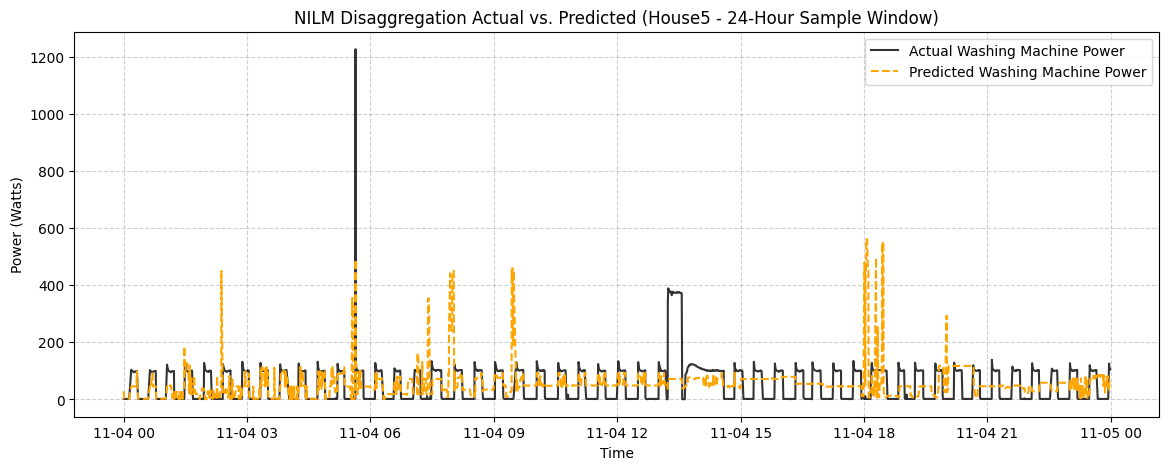

In [5]:
# Evaluation Metrics Calculation
mae_model = mean_absolute_error(y_test, y_pred)
mae_base = mean_absolute_error(y_test, y_baseline)

rmse_model = np.sqrt(mean_squared_error(y_test, y_pred))
rmse_base = np.sqrt(mean_squared_error(y_test, y_baseline))

# On/Off F1-score (Active threshold > 20W)
active_threshold = 20.0
f1_model = f1_score((y_test > active_threshold), (y_pred > active_threshold))
f1_base = f1_score((y_test > active_threshold), (y_baseline > active_threshold), zero_division=0)

print("=== Disaggregation Performance Evaluation ===")
print(f"Metric             | Baseline (Always-Off) | Random Forest Model")
print(f"-----------------------------------------------------------------")
print(f"MAE (Watts)        | {mae_base:.2f} W               | {mae_model:.2f} W")
print(f"RMSE (Watts)       | {rmse_base:.2f} W               | {rmse_model:.2f} W")
print(f"On/Off F1-Score    | {f1_base:.4f}                 | {f1_model:.4f}")

# Actual vs Predicted Plot (Sample 24-hour window from Test House)
sample_window = slice("2013-11-04 00:00:00", "2013-11-04 23:59:00")
y_test_subset = y_test.loc[sample_window]
y_pred_subset = pd.Series(y_pred, index=y_test.index).loc[sample_window]

plt.figure(figsize=(14, 5))
plt.plot(y_test_subset.index, y_test_subset, label='Actual Washing Machine Power', color='black', alpha=0.8, linewidth=1.5)
plt.plot(y_test_subset.index, y_pred_subset, label='Predicted Washing Machine Power', color='orange', linestyle='--', linewidth=1.5)
plt.title(f"NILM Disaggregation Actual vs. Predicted ({test_house} - 24-Hour Sample Window)")
plt.xlabel("Time")
plt.ylabel("Power (Watts)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Failure Case Analysis**

## Failure Case Analysis & Limitations

1. **Overlapping Resistive Loads (False Positives):**
   - *Why it struggles:* Washing machines draw high power primarily due to internal water heating elements (~2000W+). Other appliances such as electric kettles, toasters, and space heaters have nearly identical resistive heating signatures. When a user boils a kettle, the aggregate power spike often misleads the model into predicting a running washing machine.
2. **Low-Power Standby and Motor Phase Confusion:**
   - *Why it struggles:* During tumbling and rinsing phases, washing machine power drops below 50W, blending seamlessly into the household's background "always-on" load (e.g., refrigerators, routers, standby devices). The model frequently misses these low-power states, resulting in fragmented cycle predictions.